# 09 · Entidades como tokens y Transformer
**Entornos:** MiniDespacho (mediano, grande) y MiniCartas · **Tiempo de ejecución:** ≤ 6 min en CPU · **Criterio de la lección:** el mini-PTCGNet es invariante al orden de las entidades, tiene ≤ 150 000 parámetros,
llega al menos a mitad de camino hacia greedy en "mediano", transfiere a "grande" y le gana ≥ 80 % al aleatorio en MiniCartas.

## 1. La idea en una frase
Cada cosa del estado (camión, pedido, criatura, opción) es un **token**, y la **autoatención** deja que cada token mire a los demás para decidir qué es relevante.

**En el sistema de Luca:** un token global, cartas en juego, resúmenes propios y del rival, y un token por opción legal, procesados por un Transformer de 2,24 M de parámetros con pointer attention al final.
**En un problema de negocio:** un token por camión y por pedido; la atención descubre qué pedido "compite" con cuál camión sin diseñar a mano esas comparaciones.

## 2. La intuición y la fórmula
Con tokens $X \in \mathbb{R}^{n\times d}$, una cabeza de atención calcula

$$\text{Attn}(X) = \text{softmax}\!\Bigl(\frac{(XW_Q)(XW_K)^\top}{\sqrt{d_h}} + M\Bigr)(XW_V), \qquad M_{ij}=-\infty \text{ si el token } j \text{ es relleno.}$$

Sin embedding posicional el bloque es **equivariante a permutaciones**: reordenar las entidades reordena las salidas y no cambia la decisión. Cada token de opción suma además el token de la entidad
a la que apunta (`option_refs`). Al final, la query sale del token global y las keys de los tokens de opción: el mismo pointer de la lección 8.

In [1]:
import os
import time
import dataclasses
import numpy as np
import torch
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, BatchObs, TorchObs, to_torch, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, normalized_score_ci, passes_lower
from rlf.eval.arena import evaluate_policy, play_games
from rlf.envs.despacho import DespachoEnv
from rlf.envs.cartas import CartasEnv
from rlf.envs.wrappers import VsOpponent
from rlf.agents.baselines import RandomPolicy, GreedyDespacho
from rlf.agents.policy import ActorCriticPolicy
from rlf.agents.ppo import PPO, PPOConfig
from rlf.nets.mlp import MLPActorCritic
from rlf.nets.pointer import PointerActorCritic
from rlf.nets.tokens import MiniPTCGNet
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
CPU = torch.device("cpu")
make_med = lambda: DespachoEnv.from_size("mediano")
make_big = lambda: DespachoEnv.from_size("grande")
make_cartas = lambda: CartasEnv()

## 3. El núcleo: un bloque de autoatención con máscara, escrito a mano
Multi-cabeza, con máscara de relleno, usando los pesos de un `nn.MultiheadAttention`; una celda comprueba que da lo mismo (diferencia máxima ≤ 1e-5).

In [2]:
def self_attention(x, pad_mask, mha):
    """x [B, n, d]; pad_mask [B, n] con True = token de relleno (se ignora). Atención multi-cabeza escrita a mano."""
    B, n, d = x.shape
    h = mha.num_heads
    qkv = x @ mha.in_proj_weight.T + mha.in_proj_bias                   # [B, n, 3d]: proyecciones Q, K, V juntas
    q, k, v = qkv.chunk(3, dim=-1)
    split = lambda t: t.reshape(B, n, h, d // h).transpose(1, 2)        # [B, h, n, d/h]
    q, k, v = split(q), split(k), split(v)
    scores = q @ k.transpose(-1, -2) / (d // h) ** 0.5                  # [B, h, n, n]
    scores = scores.masked_fill(pad_mask[:, None, None, :], float("-inf"))   # nadie atiende al relleno
    out = torch.softmax(scores, dim=-1) @ v                             # promedio ponderado de los valores
    out = out.transpose(1, 2).reshape(B, n, d)
    return out @ mha.out_proj.weight.T + mha.out_proj.bias

torch.manual_seed(TRAIN_SEED)
mha = torch.nn.MultiheadAttention(64, 4, batch_first=True).eval()
x = torch.randn(5, 9, 64)
pad = torch.rand(5, 9) < 0.3
pad[:, 0] = False                                                        # al menos un token real por fila
with torch.no_grad():
    ref, _ = mha(x, x, x, key_padding_mask=pad, need_weights=False)
    mine = self_attention(x, pad, mha)
err = float((ref - mine).abs().max())
print(f"máxima diferencia entre el bloque a mano y nn.MultiheadAttention: {err:.2e}")
assert err <= 1e-5

máxima diferencia entre el bloque a mano y nn.MultiheadAttention: 1.79e-07


## 4. Entrenar y graficar la curva de aprendizaje
PPO con `MiniPTCGNet`: 100 000 pasos en "mediano" y 100 000 pasos en MiniCartas contra el aleatorio (con `VsOpponent`). Un Transformer es bastante más lento por paso que el MLP: mira el costo en el experimento 3.

mediano: aleatorio -118.2, greedy -77.5; grande: aleatorio -1763.0


mediano entrenado en 51 s (incluye evaluaciones): [(50000, np.float64(-78.4)), (100000, np.float64(-74.3))]


MiniCartas entrenado en 61 s


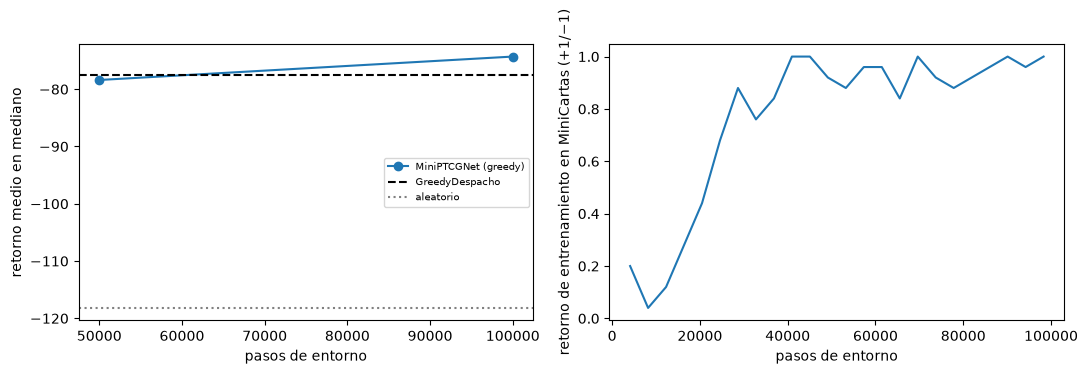

In [3]:
N = 1000
rand_med = evaluate_policy(make_med, RandomPolicy(TRAIN_SEED), N)
greedy_med = evaluate_policy(make_med, GreedyDespacho(), N)
rand_big = evaluate_policy(make_big, RandomPolicy(TRAIN_SEED), N)
print(f"mediano: aleatorio {rand_med.mean():.1f}, greedy {greedy_med.mean():.1f}; grande: aleatorio {rand_big.mean():.1f}")

torch.manual_seed(TRAIN_SEED)
net_med = MiniPTCGNet(make_med().spec)
ppo_med = PPO(net_med, PPOConfig(gamma=0.97, lam=0.9, lr=5e-4, epochs=3, minibatches=4, reward_scale=1 / 68), seed=TRAIN_SEED)
vec_med = VecEnv(make_med, 64, seed=TRAIN_SEED)
curve_med = []
t0 = time.time()
for chunk in range(2):
    ppo_med.train(vec_med, 50_000)
    curve_med.append((50_000 * (chunk + 1), evaluate_policy(make_med, ActorCriticPolicy(net_med, greedy=True), N).mean()))
print(f"mediano entrenado en {time.time() - t0:.0f} s (incluye evaluaciones):", [(s, round(r, 1)) for s, r in curve_med])

torch.manual_seed(TRAIN_SEED)
net_cartas = MiniPTCGNet(make_cartas().spec)
ppo_cartas = PPO(net_cartas, PPOConfig(gamma=1.0, lam=0.95, lr=5e-4, epochs=3, minibatches=4), seed=TRAIN_SEED)
t0 = time.time()
ppo_cartas.train(VecEnv(lambda: VsOpponent(make_cartas, RandomPolicy(0)), 64, seed=TRAIN_SEED), 100_000)
print(f"MiniCartas entrenado en {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([c[0] for c in curve_med], [c[1] for c in curve_med], marker="o", label="MiniPTCGNet (greedy)")
ax[0].axhline(greedy_med.mean(), color="k", ls="--", label="GreedyDespacho"); ax[0].axhline(rand_med.mean(), color="gray", ls=":", label="aleatorio")
ax[0].set_xlabel("pasos de entorno"); ax[0].set_ylabel("retorno medio en mediano"); ax[0].legend(fontsize=7)
ax[1].plot([h["steps"] for h in ppo_cartas.history], [h["mean_return"] for h in ppo_cartas.history])
ax[1].set_xlabel("pasos de entorno"); ax[1].set_ylabel("retorno de entrenamiento en MiniCartas (+1/−1)")
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"

### Experimento 1 · ¿Cambia la salida al permutar las entidades?
**Predice:** reordenamos las filas de entidades (y reasignamos `option_refs` en consecuencia). ¿Cambian los logits? ¿Y sin reasignar las referencias?

In [4]:
def permute_entities(t, perm, remap_refs=True):
    B, E = perm.shape
    inv = torch.argsort(perm, dim=1)
    ent = t.entities.gather(1, perm[:, :, None].expand(-1, -1, t.entities.shape[2]))
    mask = t.entity_mask.gather(1, perm)
    refs = t.option_refs.clone()
    if remap_refs:
        for k in range(2):
            old = t.option_refs[:, :, k]
            refs[:, :, k] = torch.where(old >= 0, inv.gather(1, old.clamp(min=0)), old)
    return TorchObs(**{**t.__dict__, "entities": ent, "entity_mask": mask, "option_refs": refs})

def sample_torch_obs(make, n_envs=50, steps=5, batches=10, seed=3):
    vec = VecEnv(make, n_envs, seed=seed); obs = vec.reset(); rng = np.random.default_rng(seed); out = []
    for i in range(steps * batches):
        obs = vec.step(rng.integers(0, obs.n_options)).obs
        if i % steps == steps - 1:
            out.append(to_torch(obs, CPU))
    return out

def max_logit_change(net, make, remap_refs):
    worst, n = 0.0, 0
    for t in sample_torch_obs(make):
        B, E = t.entity_mask.shape
        perm = torch.stack([torch.randperm(E) for _ in range(B)])
        with torch.no_grad():
            a, _ = net.eval()(t)
            b, _ = net.eval()(permute_entities(t, perm, remap_refs))
        fix = lambda z: z.masked_fill(~t.option_mask, 0.0)
        worst = max(worst, float((fix(a) - fix(b)).abs().max())); n += B
    return worst, n

ok_perm = {}
for name, net_, make in (("mediano", net_med, make_med), ("MiniCartas", net_cartas, make_cartas)):
    w_ok, n_ok = max_logit_change(net_, make, True)
    w_bad, _ = max_logit_change(net_, make, False)
    ok_perm[name] = (w_ok, n_ok)
    print(f"{name:11s} n = {n_ok}: cambio máximo de logits con refs reasignadas {w_ok:.1e};  sin reasignar las referencias {w_bad:.2f}")
    assert w_ok <= 1e-5 and w_bad > 1e-3

mediano     n = 500: cambio máximo de logits con refs reasignadas 4.3e-06;  sin reasignar las referencias 11.12


MiniCartas  n = 500: cambio máximo de logits con refs reasignadas 1.9e-06;  sin reasignar las referencias 2.82


<details><summary>Respuesta esperada</summary>

**No cambia** (diferencia máxima ≈ 4e-6, ruido de coma flotante): sin embedding posicional, el orden de las entidades no significa nada. Pero si permutamos las entidades **sin** reasignar `option_refs`,
las referencias apuntan a otras entidades y los logits sí cambian mucho: la invarianza es del *conjunto de entidades con sus referencias*, no de un índice arbitrario.
</details>

### Experimento 2 · ¿Y sin `option_refs`?
**Predice:** con la red entrenada en "mediano", borramos las referencias en la evaluación. ¿Empeora? ¿Cuánto?

In [5]:
class NoRefs:
    def __init__(self, policy): self.policy = policy
    def act(self, obs): return self.policy.act(dataclasses.replace(obs, option_refs=-np.ones_like(obs.option_refs)))

with_refs = evaluate_policy(make_med, ActorCriticPolicy(net_med, greedy=True), N)
without = evaluate_policy(make_med, NoRefs(ActorCriticPolicy(net_med, greedy=True)), N)
d = paired_diff_ci(with_refs, without)
print(f"con refs {with_refs.mean():.1f}   sin refs {without.mean():.1f}   diferencia = {d.mean:.1f} [{d.lo:.1f}, {d.hi:.1f}]")
assert d.lo > 0

con refs -74.3   sin refs -995.3   diferencia = 921.0 [911.5, 930.6]


<details><summary>Respuesta esperada</summary>

**Colapsa** (de ≈ −74 a ≈ −995, mucho peor que el aleatorio de ≈ −118): sin `option_refs` cada token de opción pierde el vínculo con el camión y el pedido que involucra (la opción solo trae distancia, holgura y capacidad, sin saber *cuál* camión),
y la red, entrenada con esa información, decide peor. Las referencias son la forma de decirle a la red "esta opción habla de estas entidades".
</details>

### Experimento 3 · ¿Cuántos parámetros tiene y cuánto tarda un paso frente al MLP?
**Predice:** el Transformer, ¿cuántas veces más lento que un MLP en una pasada hacia adelante de 64 observaciones?

In [6]:
def n_params(m): return sum(p.numel() for p in m.parameters())
def fwd_time(net_, t, reps=30):
    with torch.no_grad():
        net_(t)
        s = time.perf_counter()
        for _ in range(reps): net_(t)
        return (time.perf_counter() - s) / reps * 1000
t64 = sample_torch_obs(make_med, 64, 5, 1)[0]
models = {"MLP (128,128)": MLPActorCritic(make_med().spec, (128, 128)), "pointer": PointerActorCritic(make_med().spec),
          "MiniPTCGNet": MiniPTCGNet(make_med().spec)}
times = {k: fwd_time(m.eval(), t64) for k, m in models.items()}
for k, m in models.items():
    print(f"{k:14s} parámetros {n_params(m):7d}   pasada de 64 observaciones: {times[k]:6.2f} ms")
ratio = times["MiniPTCGNet"] / times["MLP (128,128)"]
print(f"MiniPTCGNet / MLP = {ratio:.1f}×")
assert ratio > 2 and n_params(models["MiniPTCGNet"]) <= 150_000

MLP (128,128)  parámetros   24206   pasada de 64 observaciones:   0.10 ms
pointer        parámetros   26113   pasada de 64 observaciones:   0.45 ms
MiniPTCGNet    parámetros   76673   pasada de 64 observaciones:   2.79 ms
MiniPTCGNet / MLP = 27.0×


<details><summary>Respuesta esperada</summary>

≈ 76 700 parámetros (por debajo del tope de 150 000) y una pasada ≈ 20 veces más lenta que la del MLP (3,2 ms frente a 0,15 ms; el ratio exacto depende de la CPU). La atención paga por comparar
todos los tokens con todos (≈ 21 tokens en "mediano"). En el sistema de Luca, con 2,24 M de parámetros, es lo que hace costoso entrenar; a cambio, la red no está atada a un tamaño ni a un orden.
</details>

### Experimento 4 · ¿Ve la red las filas de relleno?
**Predice:** si llenamos de ruido las filas de entidades y opciones que son relleno, ¿cambian los logits de las opciones legales?

In [7]:
worst = 0.0
for t in sample_torch_obs(make_med, 50, 6, 4):
    junk_e = torch.where(t.entity_mask[:, :, None], t.entities, torch.randn_like(t.entities) * 5)
    junk_o = torch.where(t.option_mask[:, :, None], t.options, torch.randn_like(t.options) * 5)
    with torch.no_grad():
        a, _ = net_med.eval()(t)
        b, _ = net_med.eval()(TorchObs(**{**t.__dict__, "entities": junk_e, "options": junk_o}))
    worst = max(worst, float((a.masked_fill(~t.option_mask, 0) - b.masked_fill(~t.option_mask, 0)).abs().max()))
print(f"cambio máximo de logits al cambiar el relleno por ruido: {worst:.1e}")
assert worst <= 1e-5

cambio máximo de logits al cambiar el relleno por ruido: 0.0e+00


<details><summary>Respuesta esperada</summary>

**No cambian** (diferencia exactamente 0 en esta medición): la máscara `key_padding_mask` impide que ningún token real atienda al relleno. Por eso una misma red puede procesar entornos con distinto número de entidades y opciones.
</details>

## 6. Criterio de la lección

In [8]:
# (a) invarianza a permutaciones: n = 1000 observaciones (500 de cada entorno), cambio de logits ≤ 1e-5
n_perm = sum(n for _, n in ok_perm.values())
worst_perm = max(w for w, _ in ok_perm.values())
ok_a = n_perm == 1000 and worst_perm <= 1e-5
# (b) parámetros
ok_b = n_params(net_med) <= 150_000 and n_params(net_cartas) <= 150_000
# (c) mediano: s(0,5) ≥ 0,5
ret_med = evaluate_policy(make_med, ActorCriticPolicy(net_med, greedy=True), N)
score = normalized_score_ci(ret_med, rand_med, greedy_med, alpha=0.5)
ok_c = passes_lower(score, 0.0)
# (d) grande, sin reentrenar
ret_big = evaluate_policy(make_big, ActorCriticPolicy(net_med, greedy=True), N)
d_big = paired_diff_ci(ret_big, rand_big)
ok_d = passes_lower(d_big, 1e-12)
# (e) MiniCartas contra el aleatorio
match = play_games(make_cartas, ActorCriticPolicy(net_cartas, greedy=True), RandomPolicy(TRAIN_SEED), N)
ok_e = match.n == N and passes_lower(match.win_rate_a, 0.80)
print(f"{'afirmación':88s} resultado")
print(f"{'(a) invarianza: cambio máx. de logits %.1e ≤ 1e-5 en %d observaciones' % (worst_perm, n_perm):88s} {ok_a}")
print(f"{'(b) parámetros: %d (mediano) y %d (MiniCartas) ≤ 150 000' % (n_params(net_med), n_params(net_cartas)):88s} {ok_b}")
print(f"{'(c) mediano: s(0,5) — media de d_i %.2f, IC95 [%.2f, %.2f], LB ≥ 0' % (score.mean, score.lo, score.hi):88s} {ok_c}")
print(f"{'(d) grande sin reentrenar: transformer − aleatorio = %.1f [%.1f, %.1f], LB > 0' % (d_big.mean, d_big.lo, d_big.hi):88s} {ok_d}")
print(f"{'(e) MiniCartas vs aleatorio: %.3f, IC95 [%.3f, %.3f], LB ≥ 0,80' % (match.win_rate_a.mean, match.win_rate_a.lo, match.win_rate_a.hi):88s} {ok_e}")
assert ok_a and ok_b and ok_c and ok_d and ok_e

afirmación                                                                               resultado
(a) invarianza: cambio máx. de logits 4.3e-06 ≤ 1e-5 en 1000 observaciones               True
(b) parámetros: 76673 (mediano) y 79361 (MiniCartas) ≤ 150 000                           True
(c) mediano: s(0,5) — media de d_i 23.53, IC95 [21.45, 25.60], LB ≥ 0                    True
(d) grande sin reentrenar: transformer − aleatorio = 124.8 [115.4, 134.1], LB > 0        True
(e) MiniCartas vs aleatorio: 0.991, IC95 [0.983, 0.995], LB ≥ 0,80                       True


## 7. Resumen y puente a la lección siguiente
- Entidades y opciones como tokens + autoatención con máscara: invariante al orden, ciega al relleno y no atada a un tamaño de entorno.
- Con ≈ 76 000 parámetros y solo 100 000 pasos de PPO, el mini-PTCGNet juega a nivel de greedy en "mediano", transfiere a "grande" y domina al aleatorio en MiniCartas.
- **Lección 10:** contra un aleatorio es fácil. Ahora dos jugadores que mejoran a la vez: **self-play** con recompensa +1/0/−1 e **información oculta** tratada con hechos y cotas, no con priors.